# 01 — Exploratory Data Analysis
**Cardiac Risk ML Module — Task A**

This notebook loads the cleaned dataset, performs all EDA using **train rows only**,
and saves plots to `reports/`.

In [1]:
import sys
from pathlib import Path

# Ensure ml/ is importable
ML_ROOT = Path(__file__).resolve().parent.parent if '__file__' in dir() else Path.cwd().parent
sys.path.insert(0, str(ML_ROOT))

import json
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src import config as cfg, data

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', font_scale=0.9)

REPORTS = cfg.REPORTS_DIR
REPORTS.mkdir(parents=True, exist_ok=True)

## Load Processed Data & Split

In [2]:
X, targets, split = data.load_processed()
train_idx = split['train_indices']
test_idx = split['test_indices']

X_train = X.iloc[train_idx].copy()
targets_train = {k: v.iloc[train_idx] for k, v in targets.items()}

print(f"Full dataset: {X.shape}")
print(f"Train set:    {X_train.shape} ({len(train_idx)} rows)")
print(f"Test set:     ({len(test_idx)} rows) -- NOT used for any EDA below")
print(f"Features:     {X.shape[1]}")

Full dataset: (303, 52)
Train set:    (242, 52) (242 rows)
Test set:     (61 rows) -- NOT used for any EDA below
Features:     52


## 1. Target Balance (Train Set)

CAD (Cath): 172/242 positive (71.1%)
LAD Stenosis: 141/242 positive (58.3%)
LCX Stenosis: 94/242 positive (38.8%)
RCA Stenosis: 91/242 positive (37.6%)


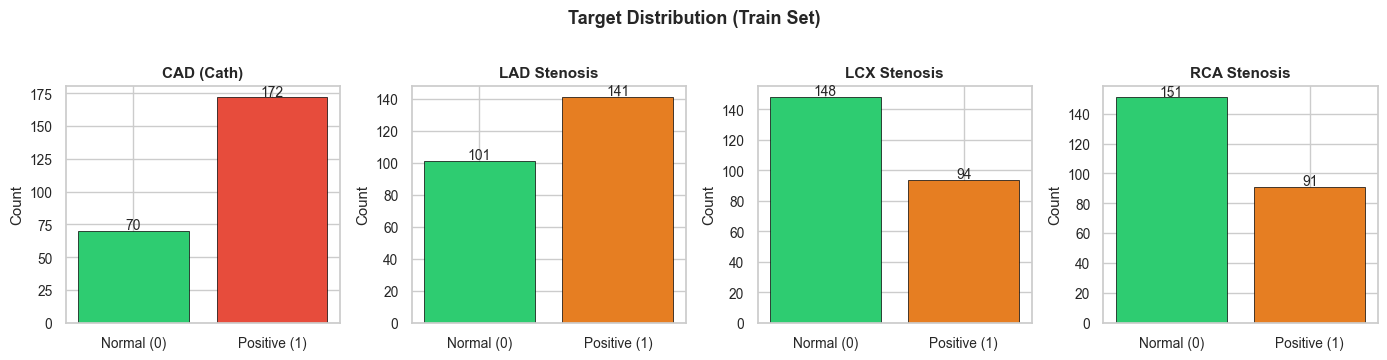

In [3]:
target_names = {
    'Cath': 'CAD (Cath)', 'LAD': 'LAD Stenosis',
    'LCX': 'LCX Stenosis', 'RCA': 'RCA Stenosis'
}

fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
colors = {'Cath': ['#2ecc71', '#e74c3c'], 'LAD': ['#2ecc71', '#e67e22'],
          'LCX': ['#2ecc71', '#e67e22'], 'RCA': ['#2ecc71', '#e67e22']}

for i, (tname, display) in enumerate(target_names.items()):
    y = targets_train[tname]
    vc = y.value_counts().sort_index()
    axes[i].bar(['Normal (0)', 'Positive (1)'], [vc.get(0, 0), vc.get(1, 0)],
                color=colors[tname], edgecolor='black', linewidth=0.5)
    axes[i].set_title(display, fontsize=11, fontweight='bold')
    axes[i].set_ylabel('Count')
    for j, v in enumerate([vc.get(0, 0), vc.get(1, 0)]):
        axes[i].text(j, v + 1, str(v), ha='center', fontsize=10)
    pct = vc.get(1, 0) / len(y) * 100
    print(f"{display}: {vc.get(1,0)}/{len(y)} positive ({pct:.1f}%)")

plt.suptitle('Target Distribution (Train Set)', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(REPORTS / 'target_balance.png', dpi=150, bbox_inches='tight')
plt.show()

## 2. Missing Values

Total missing values: 0
No missing values in any feature column.


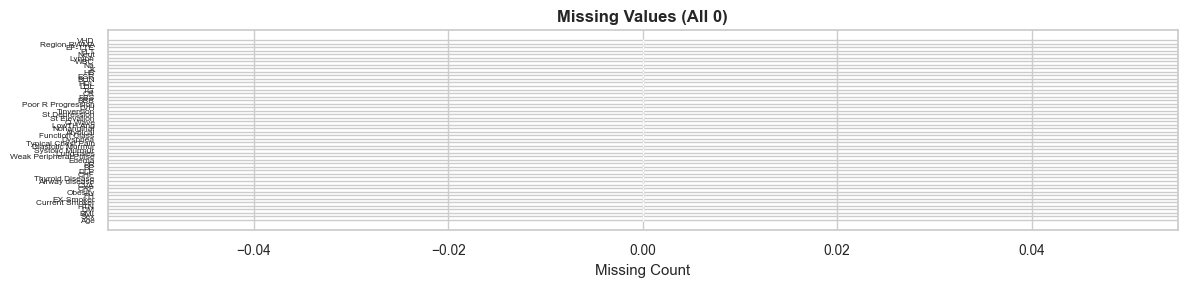

In [4]:
miss = X.isnull().sum()
print(f"Total missing values: {miss.sum()}")
if miss.sum() == 0:
    print("No missing values in any feature column.")

fig, ax = plt.subplots(figsize=(12, 3))
ax.barh(range(len(miss)), miss.values, color='#3498db')
ax.set_yticks(range(len(miss)))
ax.set_yticklabels(miss.index, fontsize=6)
ax.set_xlabel('Missing Count')
ax.set_title('Missing Values (All 0)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(REPORTS / 'missing_values.png', dpi=150, bbox_inches='tight')
plt.show()

## 3. Cath vs Vessel Status Consistency

In [5]:
df_raw = data.load_raw()
any_stenotic = (
    (df_raw['LAD'] == 'Stenotic') |
    (df_raw['LCX'] == 'Stenotic') |
    (df_raw['RCA'] == 'Stenotic')
)
cad_flag = df_raw['Cath'] == 'CAD'
mismatches = df_raw[cad_flag != any_stenotic]
print(f"Mismatches: {len(mismatches)}")
if len(mismatches) > 0:
    print(mismatches[['Cath', 'LAD', 'LCX', 'RCA']])
    print("\nRow 93: Cath=Normal but LAD=Stenotic. Genuine label inconsistency.")
    print("Likely a borderline case. Kept as-is (do not override labels).")

Mismatches: 1
      Cath       LAD     LCX     RCA
93  Normal  Stenotic  Normal  Normal

Row 93: Cath=Normal but LAD=Stenotic. Genuine label inconsistency.
Likely a borderline case. Kept as-is (do not override labels).


## 4. Obesity vs BMI

In [6]:
obesity_y = df_raw['Obesity'] == 'Y'
for thresh in [25, 30]:
    agree = ((df_raw['BMI'] >= thresh) == obesity_y).sum()
    print(f"Obesity == (BMI >= {thresh}): {agree}/303 agree ({agree/303*100:.1f}%)")

print("\nObesity matches BMI >= 25 at 99.7%, NOT BMI >= 30 (53.8%).")
print("Obesity is a clinical judgment -- KEPT as independent feature.")

Obesity == (BMI >= 25): 302/303 agree (99.7%)
Obesity == (BMI >= 30): 163/303 agree (53.8%)

Obesity matches BMI >= 25 at 99.7%, NOT BMI >= 30 (53.8%).
Obesity is a clinical judgment -- KEPT as independent feature.


## 5. Sparse Binary Columns (<10 minority)

In [7]:
print("Binary columns with minority class < 10:")
for col in X.columns:
    if X[col].dtype != 'object' and set(X[col].unique()) <= {0, 1}:
        pos = (X[col] == 1).sum()
        neg = (X[col] == 0).sum()
        if min(pos, neg) < 10:
            print(f"  {col}: Y={pos}, N={neg} (minority={min(pos, neg)})")

Binary columns with minority class < 10:
  CRF: Y=6, N=297 (minority=6)
  CVA: Y=5, N=298 (minority=5)
  Thyroid Disease: Y=7, N=296 (minority=7)
  CHF: Y=1, N=302 (minority=1)
  Weak Peripheral Pulse: Y=5, N=298 (minority=5)
  Diastolic Murmur: Y=9, N=294 (minority=9)
  LowTH Ang: Y=2, N=301 (minority=2)
  Poor R Progression: Y=9, N=294 (minority=9)


## 6. Highly Correlated Feature Pairs (|r| > 0.8)

In [8]:
X_train_num = X_train.copy()
if 'BBB' in X_train_num.columns:
    X_train_num['BBB'] = pd.Categorical(X_train_num['BBB']).codes
if 'VHD' in X_train_num.columns:
    vhd_map = {v: i for i, v in enumerate(cfg.VHD_ORDER)}
    X_train_num['VHD'] = X_train_num['VHD'].map(vhd_map)

corr_matrix = X_train_num.corr()
print("Feature pairs with |r| > 0.8:")
for i in range(len(corr_matrix.columns)):
    for j in range(i+1, len(corr_matrix.columns)):
        r = abs(corr_matrix.iloc[i, j])
        if r > 0.8:
            print(f"  {corr_matrix.columns[i]} <-> {corr_matrix.columns[j]}: |r| = {r:.4f}")

Feature pairs with |r| > 0.8:
  Lymph <-> Neut: |r| = 0.9226


## 7. Correlation Heatmap (Train Set)

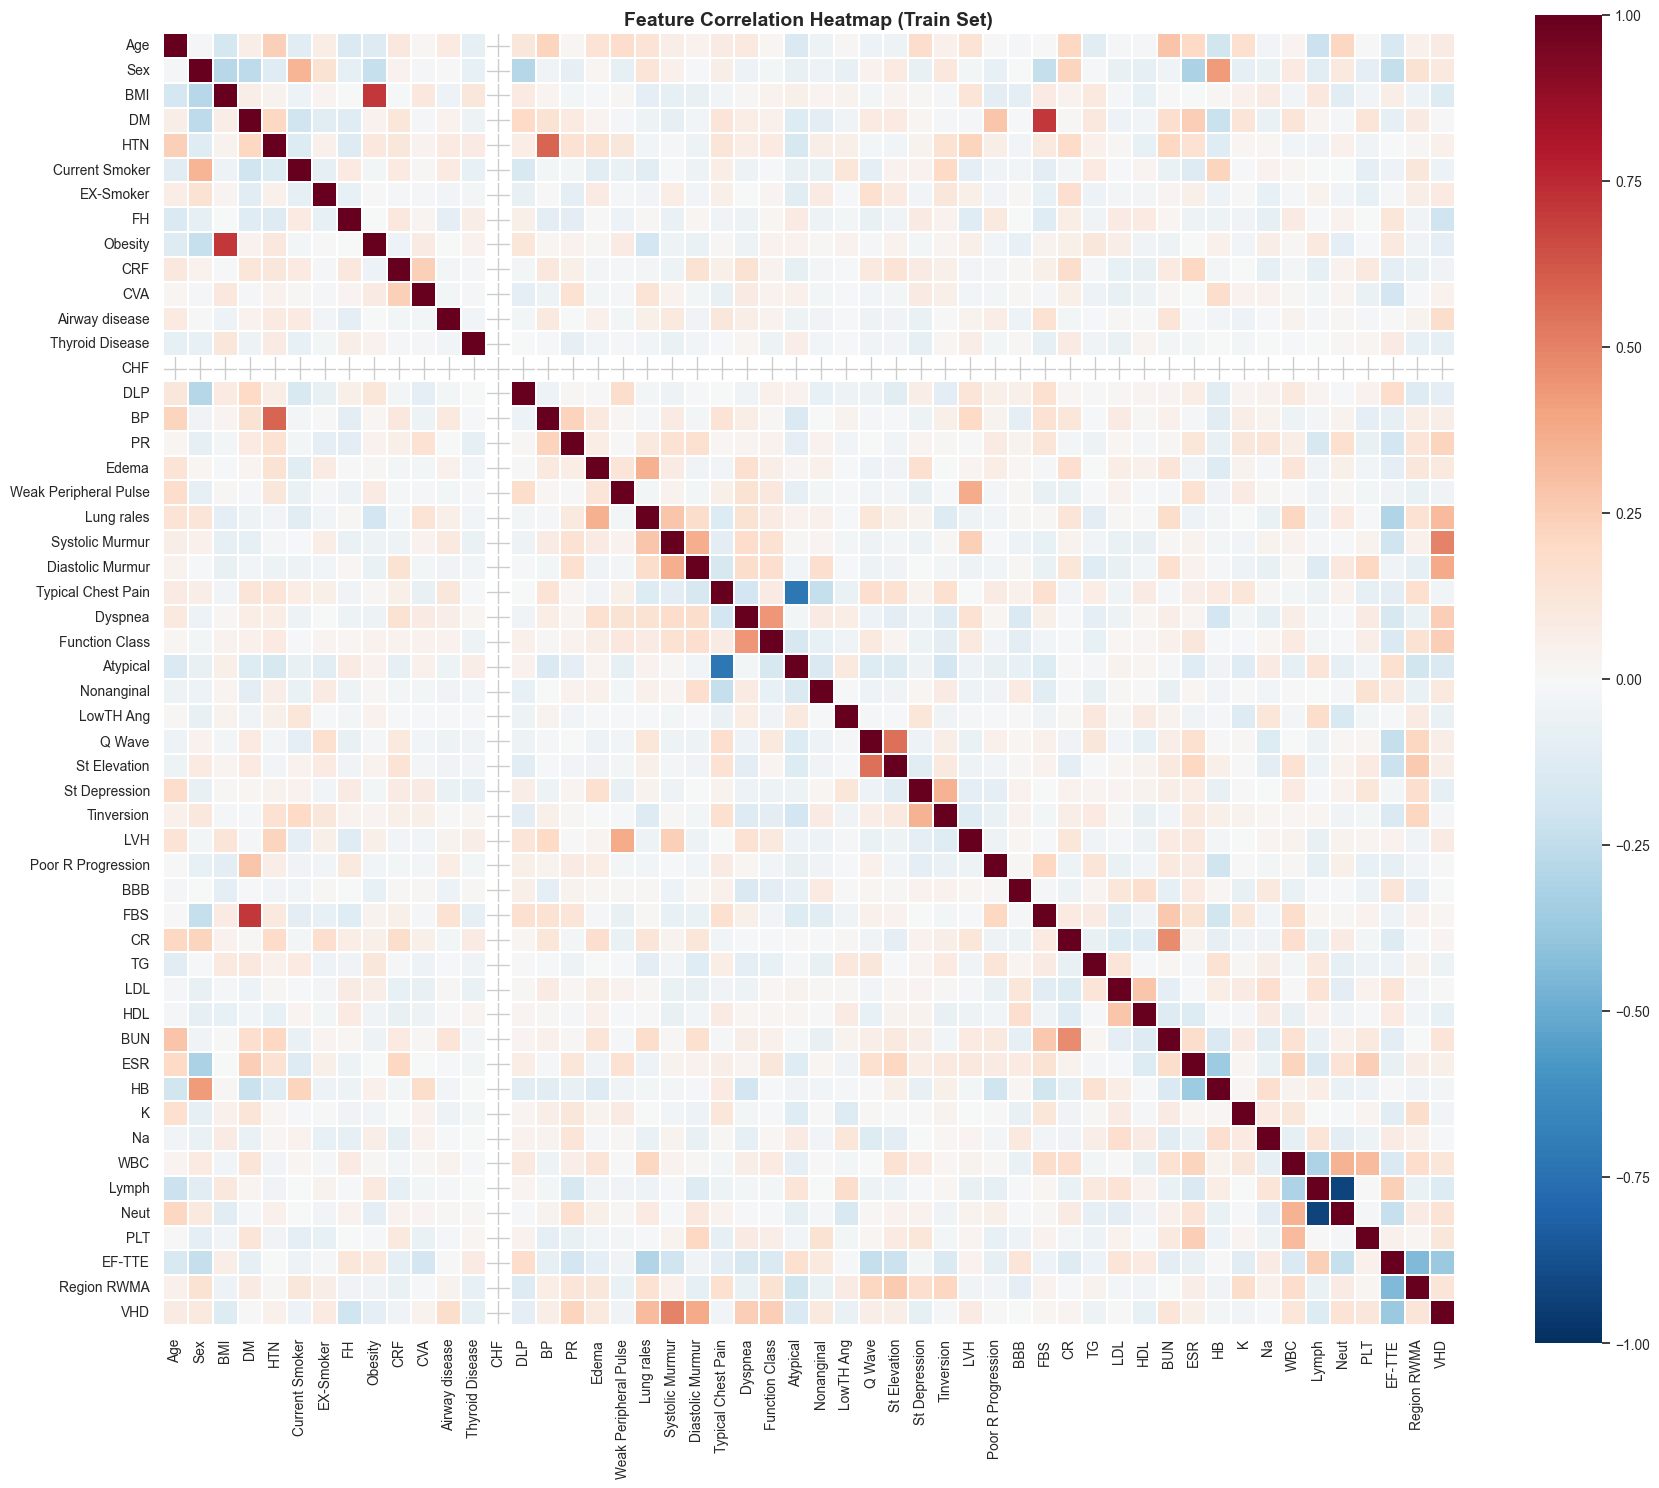

In [9]:
plt.figure(figsize=(18, 15))
sns.heatmap(corr_matrix, annot=False, cmap='RdBu_r', center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.2)
plt.title('Feature Correlation Heatmap (Train Set)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(REPORTS / 'correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

## 8. Feature-Target Correlations (Train Set)

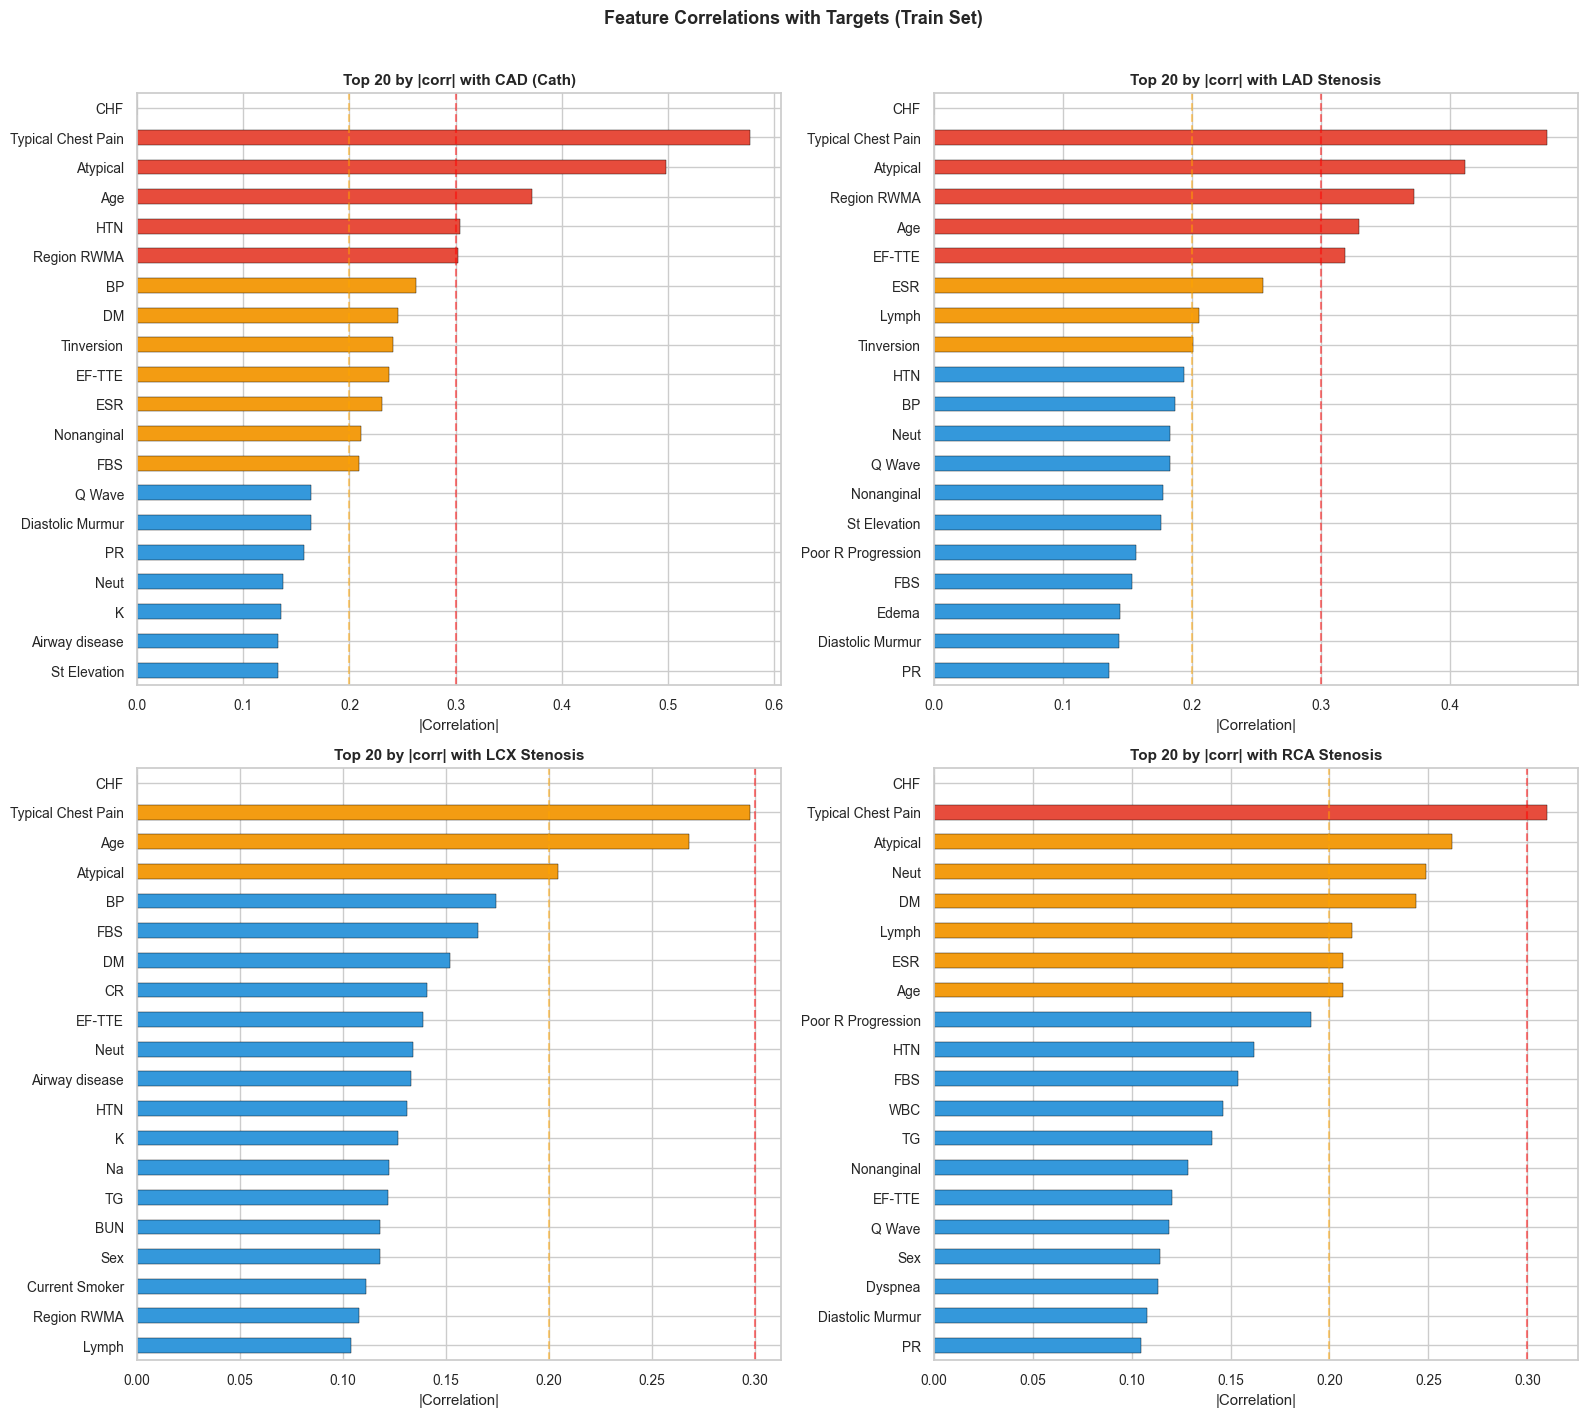

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(16, 14))
for i, (tname, display) in enumerate(target_names.items()):
    ax = axes[i // 2][i % 2]
    y_train = targets_train[tname]
    corrs = X_train_num.corrwith(y_train).abs().sort_values(ascending=True)
    top20 = corrs.tail(20)
    bar_colors = ['#e74c3c' if v > 0.3 else '#f39c12' if v > 0.2 else '#3498db'
                  for v in top20.values]
    top20.plot.barh(ax=ax, color=bar_colors, edgecolor='black', linewidth=0.3)
    ax.set_title(f'Top 20 by |corr| with {display}', fontsize=11, fontweight='bold')
    ax.set_xlabel('|Correlation|')
    ax.axvline(x=0.3, color='red', linestyle='--', alpha=0.5)
    ax.axvline(x=0.2, color='orange', linestyle='--', alpha=0.5)

plt.suptitle('Feature Correlations with Targets (Train Set)', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(REPORTS / 'feature_target_correlations.png', dpi=150, bbox_inches='tight')
plt.show()

## 9. Key Feature Distributions by CAD Status (Train Set)

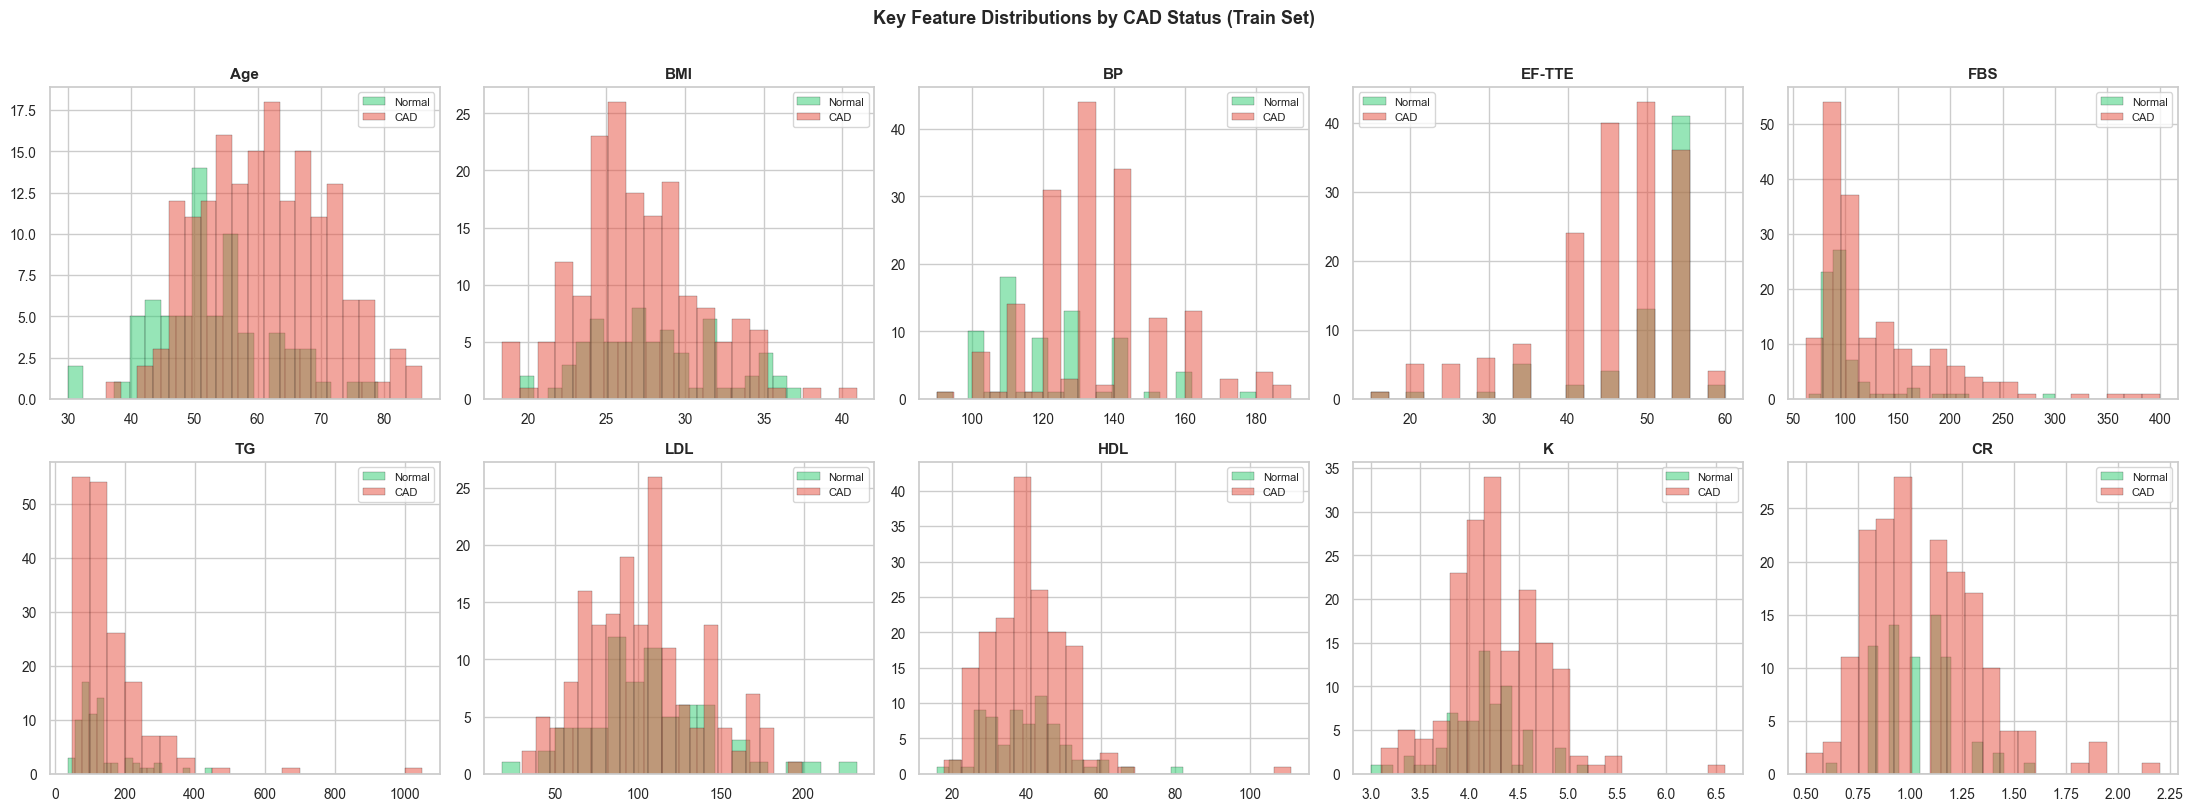

In [11]:
key_features = ['Age', 'BMI', 'BP', 'EF-TTE', 'FBS', 'TG', 'LDL', 'HDL', 'K', 'CR']
fig, axes = plt.subplots(2, 5, figsize=(22, 8))
y_cad_train = targets_train['Cath']

for i, feat in enumerate(key_features):
    ax = axes[i // 5][i % 5]
    for label, color, name in [(0, '#2ecc71', 'Normal'), (1, '#e74c3c', 'CAD')]:
        vals = X_train.loc[y_cad_train == label, feat]
        ax.hist(vals, bins=20, alpha=0.5, color=color, label=name,
                edgecolor='black', linewidth=0.3)
    ax.set_title(feat, fontsize=11, fontweight='bold')
    ax.legend(fontsize=8)

plt.suptitle('Key Feature Distributions by CAD Status (Train Set)',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(REPORTS / 'distributions_by_cad.png', dpi=150, bbox_inches='tight')
plt.show()

## 10. Feature Statistics (Train Set Only)
Saved to `data/processed/train_stats.json` for schema.py.

In [12]:
print(f"Feature statistics computed on {len(train_idx)} train rows.")
print("Saved to data/processed/train_stats.json for use in schema generation.")

Feature statistics computed on 242 train rows.
Saved to data/processed/train_stats.json for use in schema generation.
